# Análisis exploratorio · Créditos vehiculares
**Tarea 2 del reto · Soporte 3 · Rol: Análisis de datos**

Antes de construir cualquier modelo quisimos responder una pregunta sencilla: **¿qué tienen en común los clientes que no pagan la primera cuota?** Son 50 611 de 233 154 créditos, casi uno de cada cinco.

En corto, lo que encontramos: quienes no pagan suelen financiar una parte mayor del vehículo, vienen más de ciertas sucursales y tienen peor calificación en el buró. Pero ninguna de esas pistas alcanza por sí sola, porque en todos los grupos hay muchos clientes que pagan sin problema. Y la herramienta que hoy existe, la categoría del buró, no dice nada de la mitad de los clientes: no tienen historial. De ahí sale la necesidad de un modelo.

El notebook sigue ese recorrido:

| Parte | Pregunta | Gráficos |
|---|---|---|
| 1 | ¿Cómo son los créditos? | Estadísticas e histogramas |
| 2 | ¿Quiénes no pagan? | Caja, violín y barras 100 % |
| 3 | ¿Sirve la regla del buró? ¿Dónde está el riesgo? | Barras de buró y sucursal, gráfico interactivo |
| 4 | ¿Basta con mirar una variable? | Dispersión, pairplot y correlaciones |
| 5 | ¿El riesgo es igual todos los meses? | Impago por mes |

Los títulos de cada gráfico dicen el hallazgo; debajo explicamos qué vemos y por qué le importa al negocio. Usamos la misma preparación de datos que el modelo (`limpieza_datos/preparacion.py`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sys.path.insert(0, os.path.abspath("../limpieza_datos"))
import preparacion as prep

sns.set_theme(style="whitegrid")
os.makedirs("graficos", exist_ok=True)
LIMITE = prep.LIMITE_IMPAGO * 100
ORDEN_BURO = ["Muy bajo", "Bajo", "Sin puntaje", "Sin historial", "Medio", "Alto", "Muy alto"]
VERDE, ROJO = "#27ae60", "#c0392b"

df = prep.preparar(pd.read_csv("../train.csv"))          # pasos 1-5 de la limpieza
df["ESTADO"] = df["LOAN_DEFAULT"].map({0: "Paga", 1: "No paga"})
df["GRUPO_LTV"] = pd.cut(df["LTV"], [0, 60, 70, 80, 90, 100], labels=["<=60", "60-70", "70-80", "80-90", ">90"])
print(f"{len(df):,} créditos · impago total {df['LOAN_DEFAULT'].mean():.2%} (meta: impago de los aprobados < {LIMITE:.2f} %)")

233,154 créditos · impago total 21.71% (meta: impago de los aprobados < 21.71 %)


## 1 · ¿Cómo son los créditos?

In [2]:
num = ["DISBURSED_AMOUNT", "ASSET_COST", "LTV", "EDAD", "PRI_NO_OF_ACCTS", "PRI_ACTIVE_ACCTS",
       "PRI_OVERDUE_ACCTS", "PRI_SANCTIONED_AMOUNT", "HISTORIAL_CRED_M", "NO_OF_INQUIRIES"]
desc = df[num].describe(percentiles=[.25, .5, .75, .99]).T
desc["% ceros"] = (df[num] == 0).mean() * 100
display(desc.round(2))
print("Mediana de cada variable según pague o no:")
display(df.groupby("ESTADO")[num].median().T.round(1))

,count,mean,std,min,25%,50%,75%,99%,max,% ceros
DISBURSED_AMOUNT,233154.0,54356.99,12971.31,13320.00,47145.00,53803.0,60413.00,95391.00,9.905720e+05,0.00
ASSET_COST,233154.0,75865.07,18944.78,37000.00,65717.00,70946.0,79201.75,156016.00,1.628992e+06,0.00
LTV,233154.0,74.75,11.46,10.03,68.88,76.8,83.67,89.95,9.500000e+01,0.00
EDAD,233154.0,33.94,9.82,18.00,26.00,32.0,41.00,58.00,6.900000e+01,0.00
PRI_NO_OF_ACCTS,233154.0,2.44,5.22,0.00,0.00,0.0,3.00,23.00,4.530000e+02,50.16
PRI_ACTIVE_ACCTS,233154.0,1.04,1.94,0.00,0.00,0.0,1.00,9.00,1.440000e+02,58.77
PRI_OVERDUE_ACCTS,233154.0,0.16,0.55,0.00,0.00,0.0,0.00,2.00,2.500000e+01,88.73
PRI_SANCTIONED_AMOUNT,233154.0,218503.86,2374794.13,0.00,0.00,0.0,62500.00,3467119.37,1.000000e+09,59.23
HISTORIAL_CRED_M,233154.0,16.25,28.58,0.00,0.00,0.0,24.00,140.00,4.680000e+02,51.09
NO_OF_INQUIRIES,233154.0,0.21,0.71,0.00,0.00,0.0,0.00,3.00,3.600000e+01,86.62


Mediana de cada variable según pague o no:


ESTADO,No paga,Paga
DISBURSED_AMOUNT,55459.0,53303.0
ASSET_COST,71326.0,70845.0
LTV,79.1,76.0
EDAD,31.0,32.0
PRI_NO_OF_ACCTS,0.0,1.0
PRI_ACTIVE_ACCTS,0.0,0.0
PRI_OVERDUE_ACCTS,0.0,0.0
PRI_SANCTIONED_AMOUNT,0.0,0.0
HISTORIAL_CRED_M,0.0,0.0
NO_OF_INQUIRIES,0.0,0.0


Lo primero que salta a la vista es la cantidad de ceros: más de la mitad de los clientes no tiene ninguna cuenta registrada en el buró. También llama la atención que, si comparamos las medianas, quienes pagan y quienes no se parecen mucho. La única diferencia que se nota está en el LTV, así que lo miramos con más detalle.

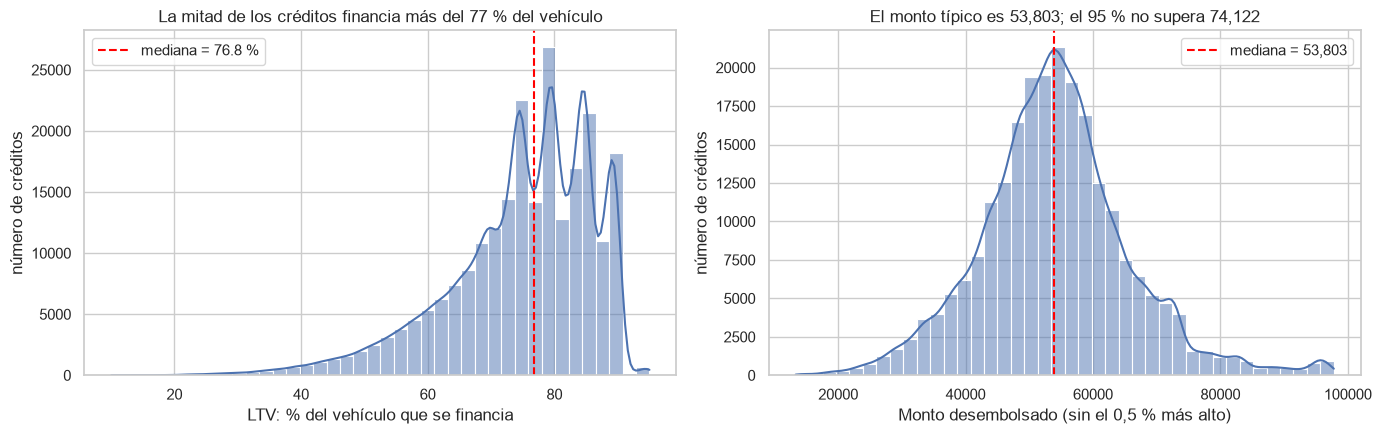

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ltv_med = df["LTV"].median()
sns.histplot(df["LTV"], bins=40, kde=True, ax=axes[0])
axes[0].axvline(ltv_med, color="red", ls="--", label=f"mediana = {ltv_med:.1f} %")
axes[0].set(xlabel="LTV: % del vehículo que se financia", ylabel="número de créditos",
            title=f"La mitad de los créditos financia más del {ltv_med:.0f} % del vehículo")
axes[0].legend()

m_med, m_p95 = df["DISBURSED_AMOUNT"].median(), df["DISBURSED_AMOUNT"].quantile(0.95)
sns.histplot(df.loc[df["DISBURSED_AMOUNT"] <= df["DISBURSED_AMOUNT"].quantile(0.995), "DISBURSED_AMOUNT"],
             bins=40, kde=True, ax=axes[1])
axes[1].axvline(m_med, color="red", ls="--", label=f"mediana = {m_med:,.0f}")
axes[1].set(xlabel="Monto desembolsado (sin el 0,5 % más alto)", ylabel="número de créditos",
            title=f"El monto típico es {m_med:,.0f}; el 95 % no supera {m_p95:,.0f}")
axes[1].legend()
plt.tight_layout(); plt.savefig("graficos/01_histogramas.png", dpi=150); plt.show()

El LTV es el porcentaje del vehículo que pone la financiera. Casi todos los créditos están entre 69 % y 84 %, y los picos en 75, 80, 85 y 90 % sugieren que se trabaja con porcentajes fijos de financiamiento. El monto, en cambio, se reparte de forma bastante pareja alrededor de 53 800.

Esto importa porque el LTV es algo que la empresa decide. Si financiar más va de la mano con no pagar, la Gerencia de Riesgo tiene una palanca concreta para mover.

## 2 · ¿Quiénes no pagan?

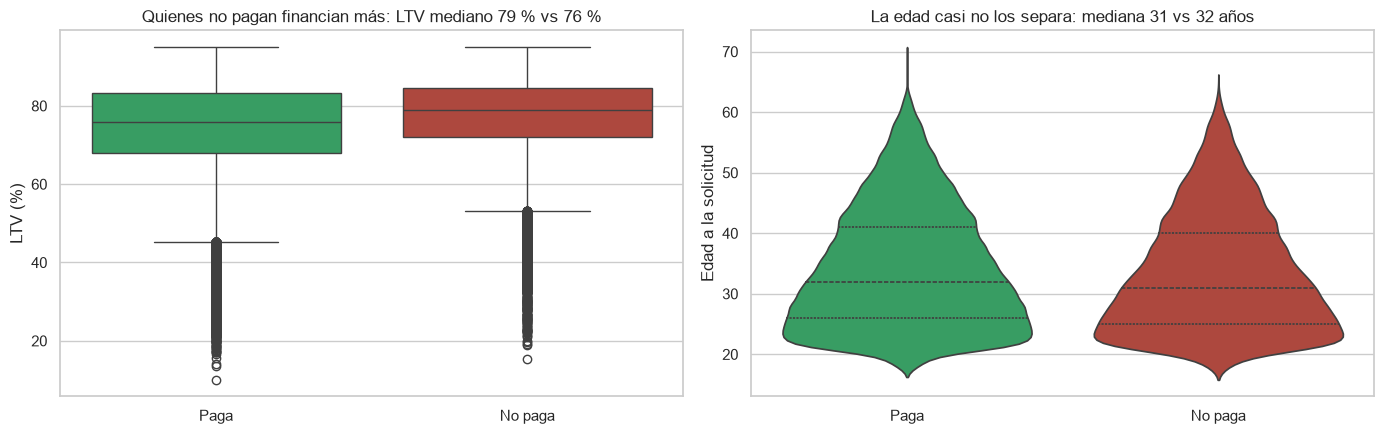

In [4]:
med = df.groupby("ESTADO")[["LTV", "EDAD"]].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="ESTADO", y="LTV", hue="ESTADO", order=["Paga", "No paga"],
            palette={"Paga": VERDE, "No paga": ROJO}, legend=False, ax=axes[0])
axes[0].set(xlabel="", ylabel="LTV (%)",
            title=f"Quienes no pagan financian más: LTV mediano {med.loc['No paga', 'LTV']:.0f} % vs {med.loc['Paga', 'LTV']:.0f} %")
sns.violinplot(data=df, x="ESTADO", y="EDAD", hue="ESTADO", order=["Paga", "No paga"], inner="quartile",
               palette={"Paga": VERDE, "No paga": ROJO}, legend=False, ax=axes[1])
axes[1].set(xlabel="", ylabel="Edad a la solicitud",
            title=f"La edad casi no los separa: mediana {med.loc['No paga', 'EDAD']:.0f} vs {med.loc['Paga', 'EDAD']:.0f} años")
plt.tight_layout(); plt.savefig("graficos/02_box_violin.png", dpi=150); plt.show()

Y sí va de la mano. La mitad de los clientes que no pagaron financiaba más del 79 % del vehículo; entre los que pagaron, ese punto está en 76 %. No parece una gran diferencia, pero se ve en toda la caja, no solo en la mediana.

Con la edad pasa lo contrario: los dos violines son casi idénticos (31 y 32 años de mediana). Para nosotros es una buena noticia, porque el modelo no necesita apoyarse en la edad, que es una variable delicada por el riesgo de discriminar.

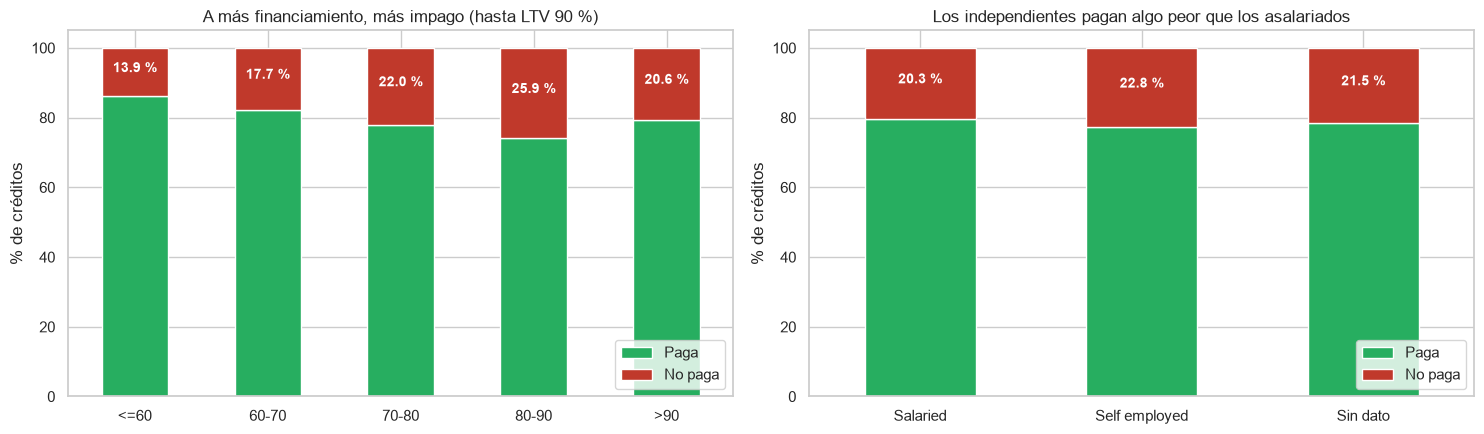

Créditos por tramo de LTV: {'<=60': 26089, '60-70': 39573, '70-80': 85604, '80-90': 81005, '>90': 883}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, titulo in [
        (axes[0], "GRUPO_LTV", "A más financiamiento, más impago (hasta LTV 90 %)"),
        (axes[1], "EMPLOYMENT_TYPE", "Los independientes pagan algo peor que los asalariados")]:
    tabla = pd.crosstab(df[col], df["ESTADO"], normalize="index")[["Paga", "No paga"]] * 100
    tabla.plot.bar(stacked=True, ax=ax, color=[VERDE, ROJO], rot=0)
    for i, v in enumerate(tabla["No paga"]):
        ax.text(i, 100 - v / 2, f"{v:.1f} %", ha="center", color="white", fontsize=10, fontweight="bold")
    ax.set(ylabel="% de créditos", xlabel="", title=titulo)
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("graficos/04_barras_apiladas.png", dpi=150); plt.show()
print("Créditos por tramo de LTV:", df["GRUPO_LTV"].value_counts(sort=False).to_dict())

Agrupando por tramos, el efecto del LTV se ve mucho más claro: entre quienes financian hasta el 60 % no pagan 14 de cada 100; entre quienes financian del 80 al 90 %, no pagan 26 de cada 100. Casi el doble.

El tramo de más del 90 % rompe la tendencia (21 de cada 100), pero son solo 883 créditos, muy pocos para sacar conclusiones. Vale la pena preguntarle al negocio si a esos clientes se les pide algo adicional.

Por tipo de empleo la diferencia es menor: no pagan 23 de cada 100 independientes frente a 20 de cada 100 asalariados.

## 3 · ¿Sirve la regla del buró? ¿Dónde está el riesgo?

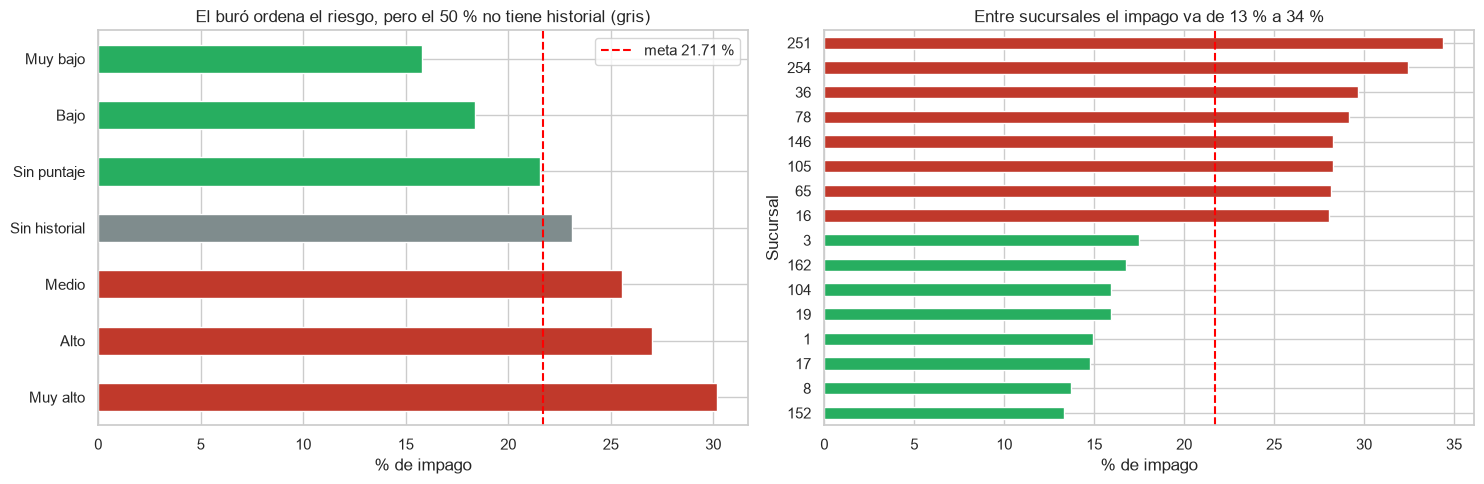

Sucursales sobre la meta: 39 de 82 (44.5% de los créditos)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
buro = df.groupby("CNS_GRUPO")["LOAN_DEFAULT"].mean().reindex(ORDEN_BURO) * 100
pct_sin = (df["CNS_GRUPO"] == "Sin historial").mean() * 100
colores = ["#7f8c8d" if c == "Sin historial" else (ROJO if v > LIMITE else VERDE) for c, v in buro.items()]
buro.plot.barh(ax=axes[0], color=colores)
linea_meta = axes[0].axvline(LIMITE, color="red", ls="--", label=f"meta {LIMITE:.2f} %")
axes[0].invert_yaxis(); axes[0].legend(handles=[linea_meta])
axes[0].set(xlabel="% de impago", ylabel="",
            title=f"El buró ordena el riesgo, pero el {pct_sin:.0f} % no tiene historial (gris)")

suc = df.groupby("BRANCH_ID")["LOAN_DEFAULT"].agg(["size", "mean"])
suc = suc[suc["size"] >= 1000].sort_values("mean")
extremos = pd.concat([suc.head(8), suc.tail(8)])["mean"] * 100
extremos.plot.barh(ax=axes[1], color=np.where(extremos > LIMITE, ROJO, VERDE))
axes[1].axvline(LIMITE, color="red", ls="--")
axes[1].set(xlabel="% de impago", ylabel="Sucursal",
            title=f"Entre sucursales el impago va de {suc['mean'].min()*100:.0f} % a {suc['mean'].max()*100:.0f} %")
plt.tight_layout(); plt.savefig("graficos/03_barras_buro_sucursal.png", dpi=150); plt.show()
sobre = df.groupby("BRANCH_ID")["LOAN_DEFAULT"].agg(["size", "mean"])
print(f"Sucursales sobre la meta: {(sobre['mean'] * 100 > LIMITE).sum()} de {len(sobre)} "
      f"({sobre.loc[sobre['mean'] * 100 > LIMITE, 'size'].sum() / sobre['size'].sum():.1%} de los créditos)")

Este es probablemente el gráfico más importante del análisis.

A la izquierda, el buró funciona como uno esperaría: a peor calificación, más impago (de 16 de cada 100 en "muy bajo" a 30 de cada 100 en "muy alto"). El problema es la barra gris. La mitad de los clientes no tiene historial y su impago (23 de cada 100) está por encima de la meta. Con la regla del buró, la empresa queda entre dos malas opciones: rechazar a todos esos clientes y perder la mitad del negocio, o aprobarlos y no cumplir la meta.

A la derecha, las sucursales muestran diferencias enormes: en la 152 no pagan 13 de cada 100 clientes; en la 251, 34. Casi la mitad de las sucursales (39 de 82, que originan el 44,5 % de los créditos) está por encima de la meta. Ojo: esto no quiere decir que esas sucursales trabajen mal; pueden atender zonas o clientes distintos. Pero es información útil para las dos gerencias.

In [7]:
suc = (df.groupby("BRANCH_ID")
         .agg(creditos=("LOAN_DEFAULT", "size"), impago=("LOAN_DEFAULT", "mean"),
              monto_total=("DISBURSED_AMOUNT", "sum"), ltv_medio=("LTV", "mean"))
         .reset_index())
suc["impago"] *= 100
fig = px.scatter(suc, x="creditos", y="impago", size="monto_total", color="ltv_medio",
                 hover_data=["BRANCH_ID", "ltv_medio"], color_continuous_scale="RdYlGn_r",
                 labels={"creditos": "Créditos", "impago": "% de impago", "ltv_medio": "LTV medio"},
                 title="Hay sucursales grandes muy por encima y muy por debajo de la meta: dónde crecer y dónde revisar")
fig.add_hline(y=LIMITE, line_dash="dash", line_color="red", annotation_text="meta 21,71 %")
fig.write_html("graficos/08_sucursales_interactivo.html", include_plotlyjs="cdn")
print("Correlación LTV medio vs impago por sucursal (>= 1 000 créditos):",
      round(suc[suc["creditos"] >= 1000][["ltv_medio", "impago"]].corr().iloc[0, 1], 2))
fig.show()

Correlación LTV medio vs impago por sucursal (>= 1 000 créditos): -0.1


En la versión interactiva (se puede pasar el mouse por cada burbuja) se ve que el problema no está solo en sucursales pequeñas. Hay sucursales grandes, como la 36, la 146 y la 16, con más de 5 000 créditos y un impago de 28 % a 30 %. Y hay otras igual de grandes, como la 152, la 1 y la 8, con 13 % a 15 %.

Pensamos que la diferencia vendría del LTV, pero no: el LTV promedio de cada sucursal casi no tiene relación con su impago (correlación de −0,1). Hay algo propio de cada canal que no está en los datos. Para Ventas, la lectura es dónde vale la pena crecer; para Riesgo, qué sucursales conviene revisar. Este mismo gráfico está en el tablero.

## 4 · ¿Basta con mirar una variable?

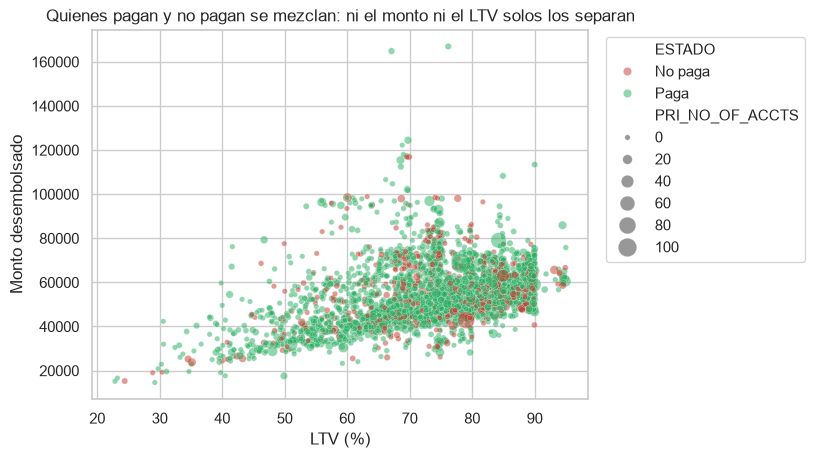

In [8]:
muestra = df.sample(4000, random_state=42)   # muestra para que el gráfico sea legible
ax = sns.scatterplot(data=muestra, x="LTV", y="DISBURSED_AMOUNT", hue="ESTADO", size="PRI_NO_OF_ACCTS",
                     sizes=(15, 200), alpha=0.5, palette={"Paga": VERDE, "No paga": ROJO})
ax.set(xlabel="LTV (%)", ylabel="Monto desembolsado",
       title="Quienes pagan y no pagan se mezclan: ni el monto ni el LTV solos los separan")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("graficos/05_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

Si el LTV y el monto bastaran para separar a los buenos de los malos pagadores, veríamos una zona roja y otra verde. Lo que vemos es una mezcla: hay clientes que no pagaron en todas partes del gráfico. Ninguna variable, por sí sola, sirve para decidir a quién aprobar.

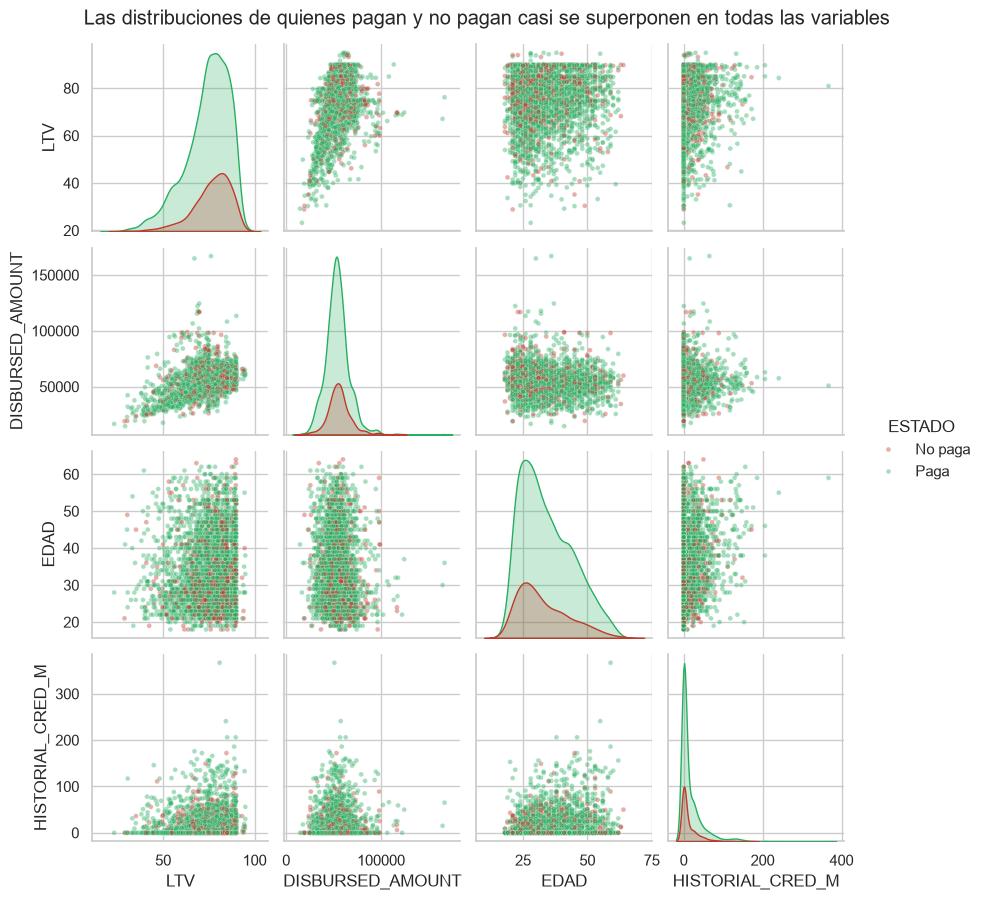

In [9]:
clave = ["LTV", "DISBURSED_AMOUNT", "EDAD", "HISTORIAL_CRED_M"]
g = sns.pairplot(df.sample(3000, random_state=42)[clave + ["ESTADO"]], hue="ESTADO", height=2.2,
                 plot_kws={"alpha": 0.4, "s": 12}, palette={"Paga": VERDE, "No paga": ROJO})
g.figure.suptitle("Las distribuciones de quienes pagan y no pagan casi se superponen en todas las variables", y=1.02)
g.savefig("graficos/07_pairplot.png", dpi=120, bbox_inches="tight"); plt.show()

El pairplot lo confirma desde otro ángulo: en la diagonal, las curvas de quienes pagan y de quienes no casi se montan una sobre otra en las cuatro variables. La información existe, pero está repartida en muchas señales pequeñas. Combinar señales pequeñas es justo lo que hace bien un modelo y lo que una regla simple no puede hacer.

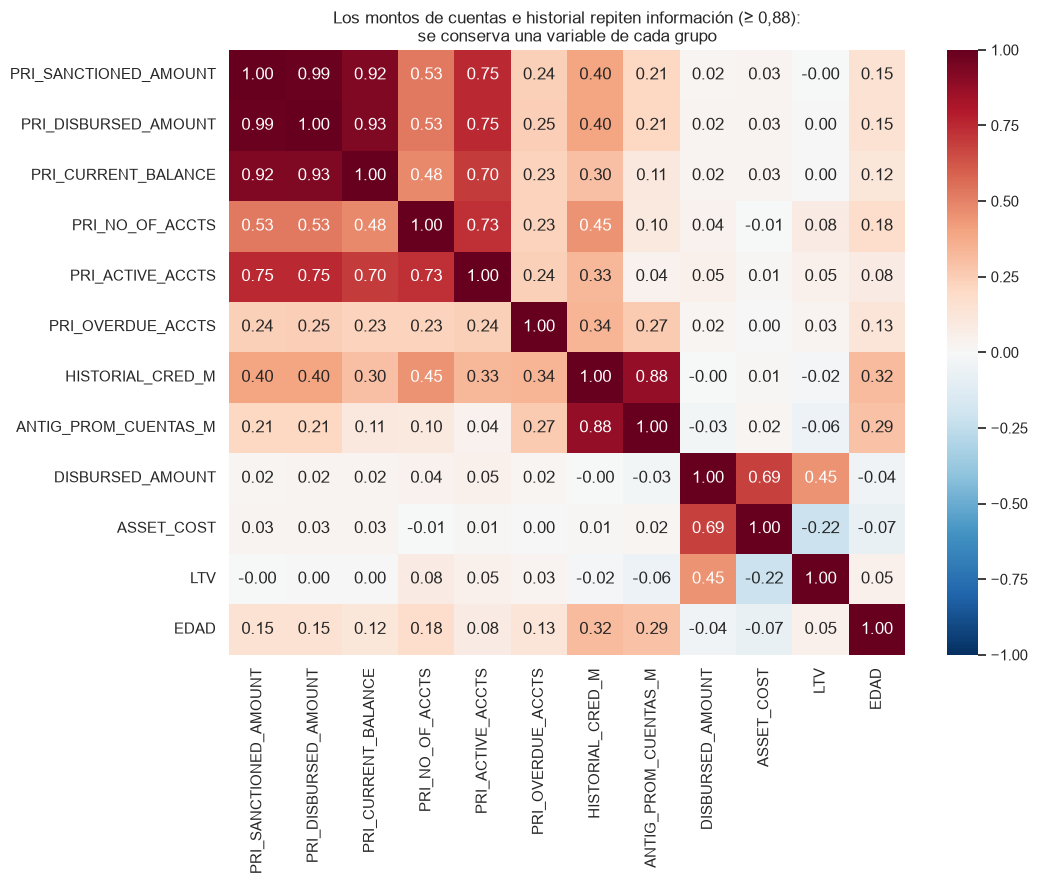

In [10]:
cols = ["PRI_SANCTIONED_AMOUNT", "PRI_DISBURSED_AMOUNT", "PRI_CURRENT_BALANCE", "PRI_NO_OF_ACCTS",
        "PRI_ACTIVE_ACCTS", "PRI_OVERDUE_ACCTS", "HISTORIAL_CRED_M", "ANTIG_PROM_CUENTAS_M",
        "DISBURSED_AMOUNT", "ASSET_COST", "LTV", "EDAD"]
corr = df[df["PRI_NO_OF_ACCTS"] > 0][cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Los montos de cuentas e historial repiten información (≥ 0,88):\nse conserva una variable de cada grupo")
plt.tight_layout(); plt.savefig("graficos/06_correlaciones.png", dpi=150); plt.show()

Esta matriz la usamos para limpiar. Miramos solo a los clientes con historial, porque los ceros de quienes no lo tienen hacen que todo parezca correlacionado. Aun así, el monto aprobado, el desembolsado y el saldo de las cuentas se mueven casi juntos (0,92 a 0,99), y lo mismo pasa con la antigüedad del historial y la antigüedad promedio de las cuentas (0,88). Guardar todas sería repetir la misma información con otro nombre, así que dejamos una de cada grupo.

## 5 · ¿El riesgo es igual todos los meses?

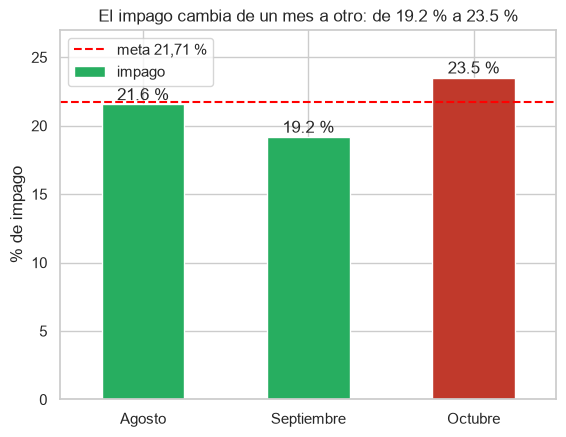

In [11]:
mes = df.groupby("MES")["LOAN_DEFAULT"].agg(creditos="size", impago="mean")
mes["impago"] *= 100
ax = mes["impago"].plot.bar(color=[VERDE if v < LIMITE else ROJO for v in mes["impago"]], rot=0)
ax.axhline(LIMITE, color="red", ls="--", label="meta 21,71 %")
ax.set_xticklabels(["Agosto", "Septiembre", "Octubre"])
for i, v in enumerate(mes["impago"]):
    ax.text(i, v + 0.3, f"{v:.1f} %", ha="center")
ax.set(xlabel="", ylabel="% de impago", ylim=(0, 27),
       title=f"El impago cambia de un mes a otro: de {mes['impago'].min():.1f} % a {mes['impago'].max():.1f} %")
ax.legend()
plt.savefig("graficos/09_impago_mes.png", dpi=150, bbox_inches="tight"); plt.show()

No lo es: no pagaron 21,6 de cada 100 en agosto, 19,2 en septiembre y 23,5 en octubre. Por eso no mezclamos los meses al entrenar: el modelo aprende con agosto y septiembre y lo probamos con octubre, como si se usara en un mes que todavía no conoce.

Este gráfico también nos avisó de algo que después confirmamos en el modelado: un modelo que aprende en meses tranquilos se queda corto cuando llega un mes malo.

## Lo que nos llevamos de este análisis
1. **Financiar más se paga en riesgo.** Entre quienes financian hasta el 60 % del vehículo no pagan 14 de cada 100; entre quienes financian del 80 al 90 %, 26 de cada 100.
2. **La sucursal importa, y mucho.** El impago va de 13 % a 34 % según la sucursal, y 39 de las 82 sucursales, que originan el 44,5 % de los créditos, están por encima de la meta.
3. **La regla del buró no alcanza.** Ordena bien el riesgo de quienes tienen historial, pero la mitad de los clientes no lo tiene y ahí la regla no distingue a nadie.

**Lo que no podemos afirmar con estos datos:** que una sucursal o un perfil *cause* el impago (solo vemos que van juntos), ni cómo habrían pagado las personas a quienes se les negó el crédito, porque el archivo solo trae créditos aprobados.

El siguiente paso, en `modelado/modelado.ipynb`, es construir un modelo que combine estas señales.